In [6]:

from google.colab import files

uploaded = files.upload()



Saving individual+household+electric+power+consumption.zip to individual+household+electric+power+consumption (1).zip


In [7]:

import zipfile
import os

zip_file = next(
    name for name in uploaded.keys()
    if name.endswith(".zip")
)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall("electricity_data")

print("Dataset extracted successfully!")

for root, dirs, files_list in os.walk("electricity_data"):
    for file in files_list:
        print(os.path.join(root, file))


Dataset extracted successfully!
electricity_data/household_power_consumption.txt


In [8]:

import zipfile
import os

# Find uploaded ZIP file
zip_file = next(
    name for name in uploaded.keys()
    if name.endswith(".zip")
)

# Extract ZIP file
with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall("electricity_data")

print("Dataset extracted successfully!")

# Display extracted files
for root, dirs, files_list in os.walk("electricity_data"):
    for file in files_list:
        print(os.path.join(root, file))


Dataset extracted successfully!
electricity_data/household_power_consumption.txt


In [9]:

import pandas as pd
from pathlib import Path

# Locate the household electricity dataset
data_files = list(
    Path("electricity_data").rglob("household_power_consumption.txt")
)

print("Dataset files found:", data_files)

# Load the dataset
df = pd.read_csv(
    data_files[0],
    sep=";",
    na_values=["?"],
    low_memory=False
)

# Display dataset details
print("\nDataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Dataset files found: [PosixPath('electricity_data/household_power_consumption.txt')]

Dataset Shape: (2075259, 9)

First 5 Records:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



Column Names:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB

Missing Values:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2   

In [10]:

import os

dataset_path = "electricity_data"

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        print("File found:", file)


File found: household_power_consumption.txt


In [11]:
import pandas as pd

file_path = "electricity_data/household_power_consumption.txt"

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    nrows=10000
)

print("Dataset shape:", df.shape)
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (10000, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



Missing values:
Date                     0
Time                     0
Global_active_power      2
Global_reactive_power    2
Voltage                  2
Global_intensity         2
Sub_metering_1           2
Sub_metering_2           2
Sub_metering_3           2
dtype: int64


In [12]:
# Check and remove missing values
print("Before cleaning:", df.shape)

df = df.dropna().copy()

print("After cleaning:", df.shape)

# Combine Date and Time into one datetime column
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True
)

# Sort records by time
df = df.sort_values("Datetime").reset_index(drop=True)

print("\nCleaned dataset:")
display(df.head())

print("\nRemaining missing values:")
print(df.isnull().sum())

Before cleaning: (10000, 9)
After cleaning: (9998, 9)

Cleaned dataset:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00



Remaining missing values:
Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
Datetime                 0
dtype: int64


Electricity Consumption Summary:


,Global_active_power
count,9998.000000
mean,1.744016
std,1.339906
min,0.194000
25%,0.388000
50%,1.478000
75%,2.561500
max,7.884000


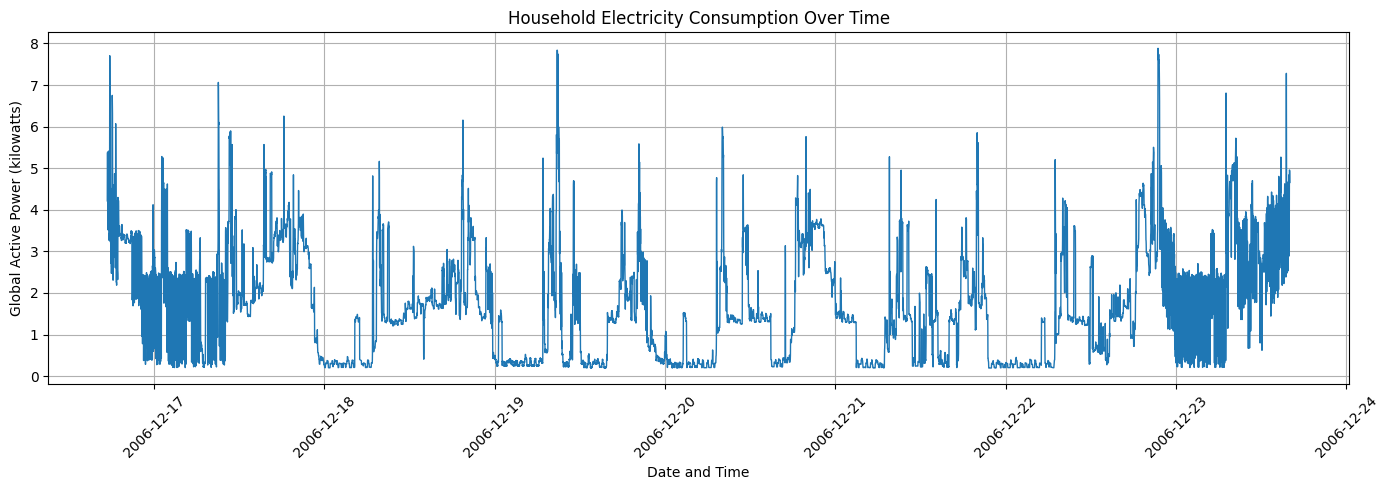

In [13]:
import matplotlib.pyplot as plt

# Basic statistical summary
print("Electricity Consumption Summary:")
display(df["Global_active_power"].describe())

# Plot electricity consumption over time
plt.figure(figsize=(14, 5))

plt.plot(
    df["Datetime"],
    df["Global_active_power"],
    linewidth=1
)

plt.title("Household Electricity Consumption Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Global Active Power (kilowatts)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Hourly dataset:


,Global_active_power
Datetime,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467
2006-12-16 22:00:00,2.200133
2006-12-16 23:00:00,2.061600
2006-12-17 00:00:00,1.882467
2006-12-17 01:00:00,3.349400



Total hourly records: 168


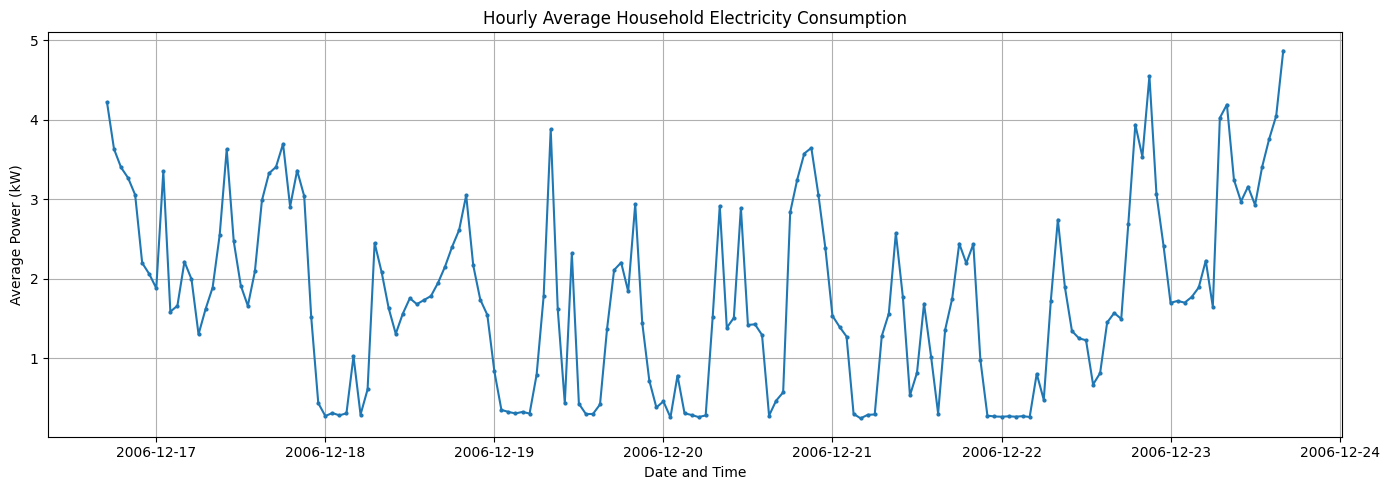

In [14]:
# Set Datetime as the index
df = df.set_index("Datetime")

# Calculate hourly average electricity consumption
hourly_data = df["Global_active_power"].resample("h").mean()

# Display the hourly dataset
print("Hourly dataset:")
display(hourly_data.head(10))

print("\nTotal hourly records:", len(hourly_data))

# Plot hourly consumption
plt.figure(figsize=(14, 5))
plt.plot(hourly_data, marker="o", markersize=2)

plt.title("Hourly Average Household Electricity Consumption")
plt.xlabel("Date and Time")
plt.ylabel("Average Power (kW)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
import pandas as pd

file_path = "electricity_data/household_power_consumption.txt"

hourly_parts = []

for chunk in pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    usecols=["Date", "Time", "Global_active_power"],
    chunksize=100000
):
    chunk["Datetime"] = pd.to_datetime(
        chunk["Date"] + " " + chunk["Time"],
        dayfirst=True,
        errors="coerce"
    )

    chunk["Global_active_power"] = pd.to_numeric(
        chunk["Global_active_power"],
        errors="coerce"
    )

    chunk = chunk.dropna(
        subset=["Datetime", "Global_active_power"]
    )

    chunk = chunk.set_index("Datetime")

    hourly_parts.append(
        chunk["Global_active_power"]
        .resample("h")
        .agg(["sum", "count"])
    )

# Combine hourly results from all chunks
hourly_full = pd.concat(hourly_parts).groupby(level=0).sum()

# Calculate hourly averages
hourly_full["Global_active_power"] = (
    hourly_full["sum"] / hourly_full["count"]
)

hourly_data = hourly_full["Global_active_power"]

print("Full hourly dataset shape:", hourly_data.shape)
print("\nFirst 5 records:")
display(hourly_data.head())

print("\nLast 5 records:")
display(hourly_data.tail())

Full hourly dataset shape: (34589,)

First 5 records:


,Global_active_power
Datetime,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467



Last 5 records:


,Global_active_power
Datetime,
2010-11-26 17:00:00,1.725900
2010-11-26 18:00:00,1.573467
2010-11-26 19:00:00,1.659333
2010-11-26 20:00:00,1.163700
2010-11-26 21:00:00,0.934667


In [16]:
print("Total hourly records:", len(hourly_data))

print("\nMissing values:")
print(hourly_data.isnull().sum())

print("\nDuplicate timestamps:")
print(hourly_data.index.duplicated().sum())

print("\nDate range:")
print("Start:", hourly_data.index.min())
print("End:", hourly_data.index.max())

print("\nStatistical summary:")
display(hourly_data.describe())

Total hourly records: 34589

Missing values:
421

Duplicate timestamps:
0

Date range:
Start: 2006-12-16 17:00:00
End: 2010-11-26 21:00:00

Statistical summary:


,Global_active_power
count,34168.000000
mean,1.091728
std,0.897619
min,0.124000
25%,0.341925
50%,0.802850
75%,1.579342
max,6.560533


In [17]:
# Identify consecutive missing-hour periods
missing = hourly_data.isna()

missing_dates = missing[missing].index

missing_df = pd.DataFrame(index=missing_dates)
missing_df["group"] = (
    missing_df.index.to_series()
    .diff()
    .ne(pd.Timedelta(hours=1))
    .cumsum()
)

missing_runs = missing_df.groupby("group").apply(
    lambda group: pd.Series({
        "Start": group.index.min(),
        "End": group.index.max(),
        "Missing_Hours": len(group)
    })
)

print("Number of missing periods:", len(missing_runs))
print("\nLongest missing periods:")
display(
    missing_runs.sort_values(
        "Missing_Hours", ascending=False
    ).head(10)
)

Number of missing periods: 8

Longest missing periods:


/tmp/ipykernel_3490/819000633.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  missing_runs = missing_df.groupby("group").apply(


,Start,End,Missing_Hours
group,,,
7,2010-08-17 22:00:00,2010-08-22 20:00:00,119
8,2010-09-25 04:00:00,2010-09-28 18:00:00,87
1,2007-04-28 01:00:00,2007-04-30 13:00:00,61
3,2009-06-13 01:00:00,2009-06-15 06:00:00,54
5,2010-01-12 15:00:00,2010-01-14 18:00:00,52
6,2010-03-20 04:00:00,2010-03-21 12:00:00,33
4,2009-08-13 05:00:00,2009-08-13 18:00:00,14
2,2007-07-15 17:00:00,2007-07-15 17:00:00,1


In [18]:
missing = hourly_data.isna()

groups = missing.ne(missing.shift()).cumsum()
run_lengths = missing.groupby(groups).transform("sum")

isolated_missing = missing & run_lengths.eq(1)

interpolated = hourly_data.interpolate(method="time")

hourly_clean = hourly_data.copy()
hourly_clean.loc[isolated_missing] = interpolated.loc[isolated_missing]

print("Original missing values:", hourly_data.isna().sum())
print("Isolated values filled:", isolated_missing.sum())
print("Missing values remaining:", hourly_clean.isna().sum())

Original missing values: 421
Isolated values filled: 1
Missing values remaining: 420


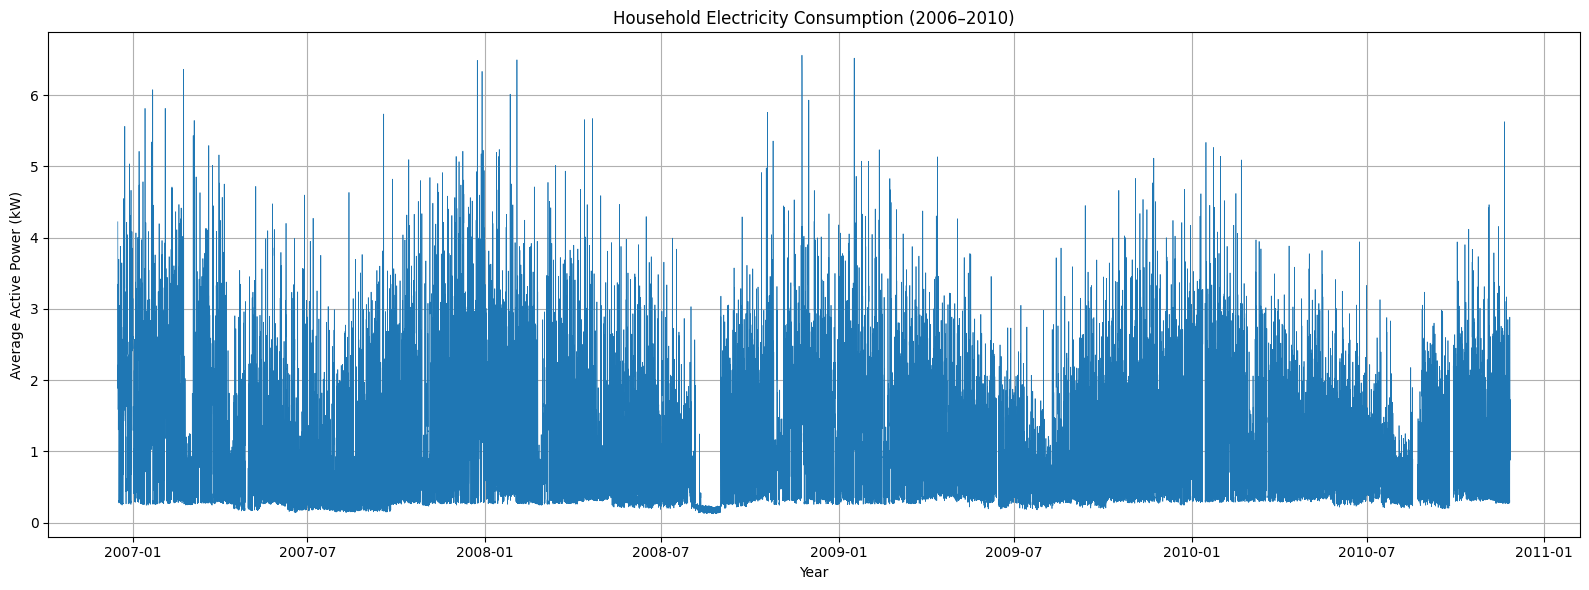

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    hourly_clean.index,
    hourly_clean,
    linewidth=0.5
)

plt.title("Household Electricity Consumption (2006–2010)")
plt.xlabel("Year")
plt.ylabel("Average Active Power (kW)")
plt.grid(True)
plt.tight_layout()
plt.show()


Total valid days: 1420

Daily consumption summary:


,mean
count,1420.000000
mean,1.091207
std,0.416546
min,0.173818
25%,0.818158
50%,1.080701
75%,1.319038
max,3.314851


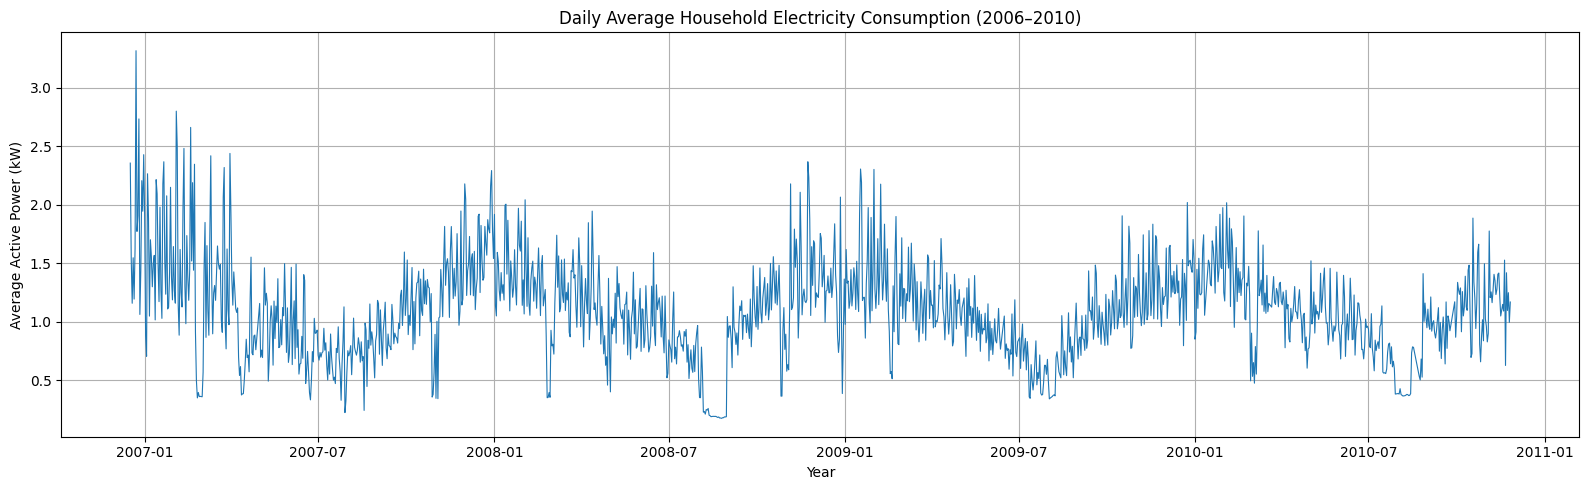

In [20]:
# Calculate daily average electricity consumption
daily_data = hourly_clean.resample("D").agg(
    ["mean", "count"]
)

# Keep days with at least 18 valid hourly readings
daily_data = daily_data[
    daily_data["count"] >= 18
]

daily_consumption = daily_data["mean"]

print("Total valid days:", len(daily_consumption))

print("\nDaily consumption summary:")
display(daily_consumption.describe())

# Plot daily consumption
plt.figure(figsize=(16, 5))

plt.plot(
    daily_consumption.index,
    daily_consumption,
    linewidth=0.8
)

plt.title("Daily Average Household Electricity Consumption (2006–2010)")
plt.xlabel("Year")
plt.ylabel("Average Active Power (kW)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
# Recreate daily data while preserving missing calendar days
daily_all = hourly_clean.resample("D").agg(
    ["mean", "count"]
)

daily_all.loc[
    daily_all["count"] < 18, "mean"
] = float("nan")

forecast_df = pd.DataFrame(
    {"Consumption": daily_all["mean"]}
)

# Previous consumption features
forecast_df["lag_1"] = forecast_df["Consumption"].shift(1)
forecast_df["lag_7"] = forecast_df["Consumption"].shift(7)

# Previous 7-day average (excluding the current day)
forecast_df["rolling_mean_7"] = (
    forecast_df["Consumption"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

# Calendar features
forecast_df["day_of_week"] = forecast_df.index.dayofweek
forecast_df["month"] = forecast_df.index.month

# Remove rows without sufficient historical data
forecast_df = forecast_df.dropna()

print("Forecasting dataset shape:", forecast_df.shape)

print("\nFirst 5 records:")
display(forecast_df.head())

print("\nMissing values:")
print(forecast_df.isnull().sum())

Forecasting dataset shape: (1364, 6)

First 5 records:


,Consumption,lag_1,lag_7,rolling_mean_7,day_of_week,month
Datetime,,,,,,
2006-12-24,1.770842,3.314851,2.354486,1.817326,6,12
2006-12-25,1.904944,1.770842,1.530435,1.733948,0,12
2006-12-26,2.732021,1.904944,1.157079,1.787450,1,12
2006-12-27,1.061639,2.732021,1.545658,2.012441,2,12
2006-12-28,1.439332,1.061639,1.192843,1.943296,3,12



Missing values:
Consumption       0
lag_1             0
lag_7             0
rolling_mean_7    0
day_of_week       0
month             0
dtype: int64


In [22]:
from sklearn.model_selection import train_test_split

# Select input features
X = forecast_df[
    ["lag_1", "lag_7", "rolling_mean_7",
     "day_of_week", "month"]
]

# Target variable
y = forecast_df["Consumption"]

# Chronological 80:20 split
split_index = int(len(forecast_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting period:")
print(X_test.index.min(), "to", X_test.index.max())


Training records: 1091
Testing records: 273

Training period:
2006-12-24 00:00:00 to 2010-01-25 00:00:00

Testing period:
2010-01-26 00:00:00 to 2010-11-26 00:00:00


In [23]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Create the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

# Predict electricity consumption
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Random Forest Model Performance")
print("--------------------------------")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

Random Forest Model Performance
--------------------------------
MAE: 0.1836
RMSE: 0.2426
R2 Score: 0.468


In [24]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Simple baseline: use previous day's consumption
baseline_pred = X_test["lag_1"]

# Baseline evaluation
baseline_mae = mean_absolute_error(y_test, baseline_pred)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

baseline_r2 = r2_score(y_test, baseline_pred)

# Compare both models
comparison = pd.DataFrame({
    "Model": ["Baseline (Previous Day)", "Random Forest"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse],
    "R2 Score": [baseline_r2, r2]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Baseline (Previous Day),0.2099,0.2900,0.2398
1,Random Forest,0.1836,0.2426,0.4680


In [25]:
baseline_pred = X_test["lag_1"]

baseline_mae = mean_absolute_error(y_test, baseline_pred)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

baseline_r2 = r2_score(y_test, baseline_pred)

comparison = pd.DataFrame({
    "Model": ["Baseline (Previous Day)", "Random Forest"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse],
    "R2 Score": [baseline_r2, r2]
})

display(comparison.round(4))


,Model,MAE,RMSE,R2 Score
0,Baseline (Previous Day),0.2099,0.2900,0.2398
1,Random Forest,0.1836,0.2426,0.4680


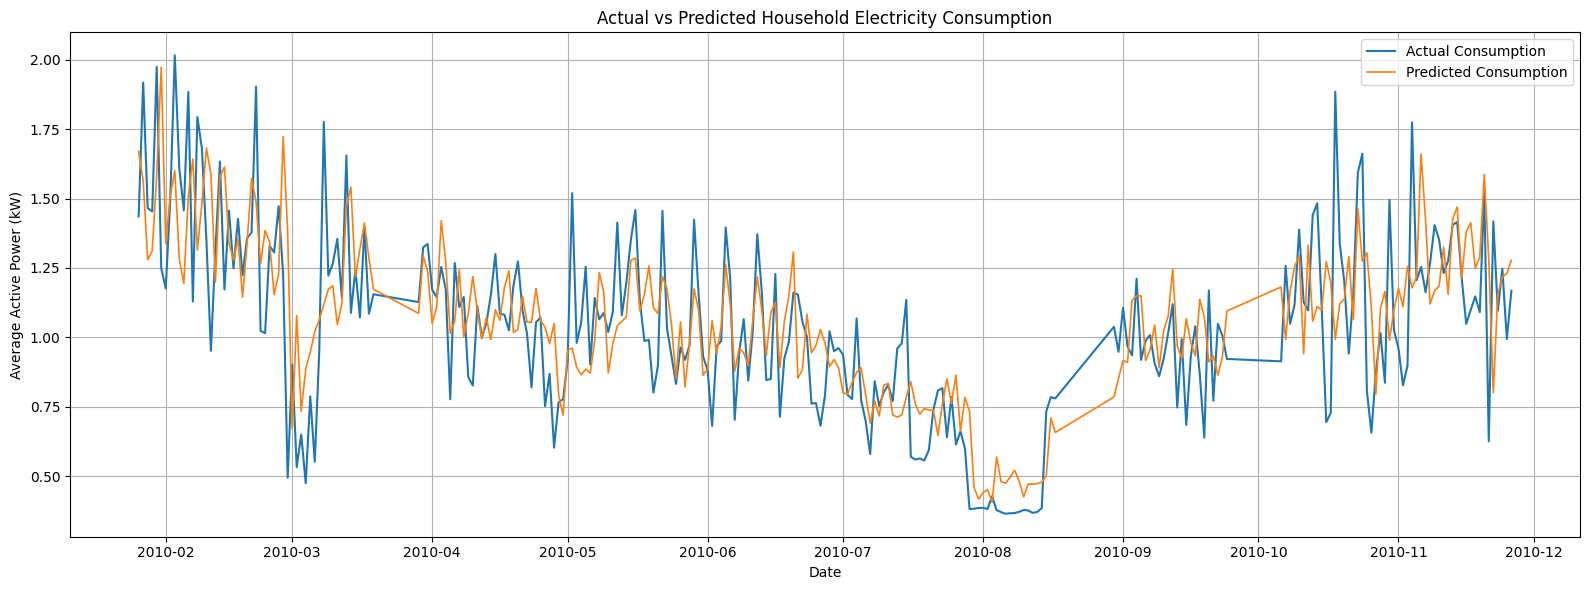

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual Consumption",
    linewidth=1.5
)

plt.plot(
    y_test.index,
    y_pred,
    label="Predicted Consumption",
    linewidth=1.2
)

plt.title("Actual vs Predicted Household Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Average Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Feature Importance:


,Feature,Importance
2,rolling_mean_7,0.4856
0,lag_1,0.2390
1,lag_7,0.1247
3,day_of_week,0.0889
4,month,0.0618


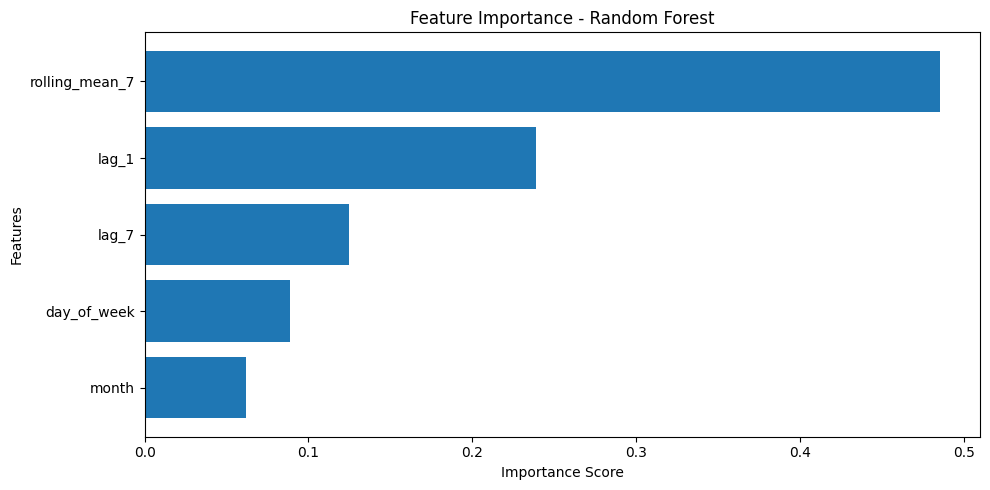

In [27]:
# Extract feature importance from Random Forest
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(importance.round(4))

# Visualise feature importance
plt.figure(figsize=(10, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [28]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Create Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train model
gb_model.fit(X_train, y_train)

# Make predictions
gb_pred = gb_model.predict(X_test)

# Evaluate model
gb_mae = mean_absolute_error(y_test, gb_pred)

gb_rmse = np.sqrt(
    mean_squared_error(y_test, gb_pred)
)

gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting Performance")
print("--------------------------------")
print("MAE:", round(gb_mae, 4))
print("RMSE:", round(gb_rmse, 4))
print("R2 Score:", round(gb_r2, 4))

Gradient Boosting Performance
--------------------------------
MAE: 0.1692
RMSE: 0.2372
R2 Score: 0.4913


In [29]:
# Calculate baseline predictions
baseline_pred = X_test["lag_1"]

# Compare model performance
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mae,
        gb_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        rmse,
        gb_rmse
    ],
    "R2 Score": [
        r2_score(y_test, baseline_pred),
        r2,
        gb_r2
    ]
})

display(results.round(4))

,Model,MAE,RMSE,R2 Score
0,Baseline,0.2099,0.2900,0.2398
1,Random Forest,0.1836,0.2426,0.4680
2,Gradient Boosting,0.1692,0.2372,0.4913


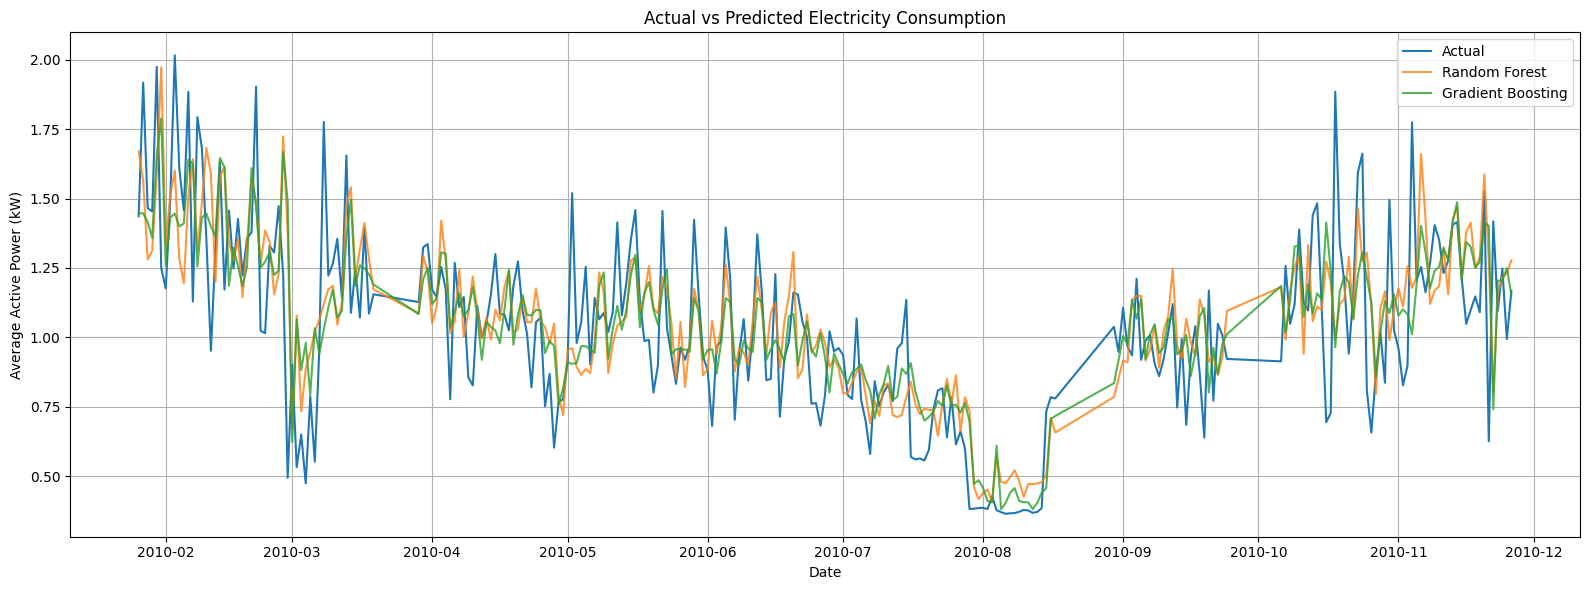

In [30]:
plt.figure(figsize=(16, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual",
    linewidth=1.5
)

plt.plot(
    y_test.index,
    y_pred,
    label="Random Forest",
    alpha=0.8
)

plt.plot(
    y_test.index,
    gb_pred,
    label="Gradient Boosting",
    alpha=0.8
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Average Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()